# Uncertainty at a location

An ensemble gives every location many predictions, one per partition, besides their mean. Those members
say how sure the estimate is, but only once we know what their spread measures. This tutorial reads the
uncertainty at each location in three ways, as the precision of the estimate, as the law of the members
and as a fitted local law widened to the spread of the data, and checks each against the truth.

## Learning goals

- What `precision()` measures, with the loss functions of Spatialize and one of your own.
- How far the precision points at the locations where the estimate is wrong.
- How to read the law at one location, from the members and from a fitted law.
- Why the members' spread follows the granularity, while a widened local law follows the field.

*How sure is the estimate at each location?*

## The idea

At a location $v$ the members $z^{(1)}(v), \dots, z^{(T)}(v)$ form an empirical law. With an averaging
decoder each member is a weighted mean of the data of one cell, so the members differ only because the
cells differ. Their spread measures how much the estimate depends on the partition, a spread that shrinks
as the cells grow, whatever the field does inside them.

The **precision** of the estimate is a loss between the estimate and its members, by default their mean
squared difference. It is a measure of that same spread.

A **fitted local law** smooths the members into a density. The theory Spatialize rests on adds a **widening**,
which mixes around each member a law whose variance makes up the variance of the nearest data, a Gamma
law for a positive variable and a skew-normal one otherwise. The members' spread then follows the
granularity, while the widened law's follows the field. The theory draws a rule from it ([Ensemble spatial simulation](https://spatialize.readthedocs.io/en/latest/theory/ess.html)). A question about
one location reads the fitted local law, while a question about the whole map reads the members.

## Step by step

### The field and the ensemble

The field is the anisotropic Gaussian simulation used across this gallery, 400 data on a 200 × 200
grid, read on every second node. The ensemble uses the sharpened adaptive IDW, an averaging decoder for a
field with a direction, at the granularity the Pareto search chooses.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

import spatialize
from spatialize.data import load_simulated_anisotropic_data
from spatialize.empirical import EmpiricalModel, FittedModelFactory
from spatialize.gs.esi import esi_griddata, esi_pareto_hparams_search
from spatialize.gs.ess import ess_sample
import spatialize.gs.esi.aggfunction as af
import spatialize.gs.esi.lossfunction as lf
import spatialize.gs.esi.scorefunction as sf
from spatialize.logging import singleton_null_callback as quiet

spatialize.session.set(empty_cells="coarsen", progress=False)

(samples, _), _, _, grid = load_simulated_anisotropic_data()
points, values = samples[["x", "y"]].values, samples["sim1"].values
truth = grid["sim1"].values.reshape(200, 200).T[::2, ::2]          # truth[i, j] at x = 2i, y = 2j
xi = np.stack(np.meshgrid(np.arange(0.0, 200.0, 2.0), np.arange(0.0, 200.0, 2.0), indexing="ij"))

alpha = esi_pareto_hparams_search(points, values, local_interpolator="sharpidw", n_partitions=[100],
                                  alpha=[0.9, 0.95, 0.98], k=5, scoring=sf.mae, seed=0).best_result(strategy="knee")["alpha"]
result = esi_griddata(points, values, xi, local_interpolator="sharpidw", n_partitions=300, alpha=alpha, seed=0)
estimate, members = result.estimation(), result.esi_samples()
print(f"alpha at the knee {alpha}, MAE against the truth {np.abs(estimate - truth).mean():.3f}")

alpha at the knee 0.95, MAE against the truth 0.450


### The precision of the estimate

`precision()` applies a loss function between the estimate and each member, then averages over the
members. Spatialize gives the mean squared and the mean absolute losses, `lossfunction.mse_loss` and
`lossfunction.mae_loss`. Any pointwise loss becomes one with the decorator `lossfunction.loss`, given the
aggregation over the members. Here a relative loss divides the absolute difference by the size of the
estimate, for a variable whose errors matter in proportion. We set each precision beside the error the
estimate actually makes.

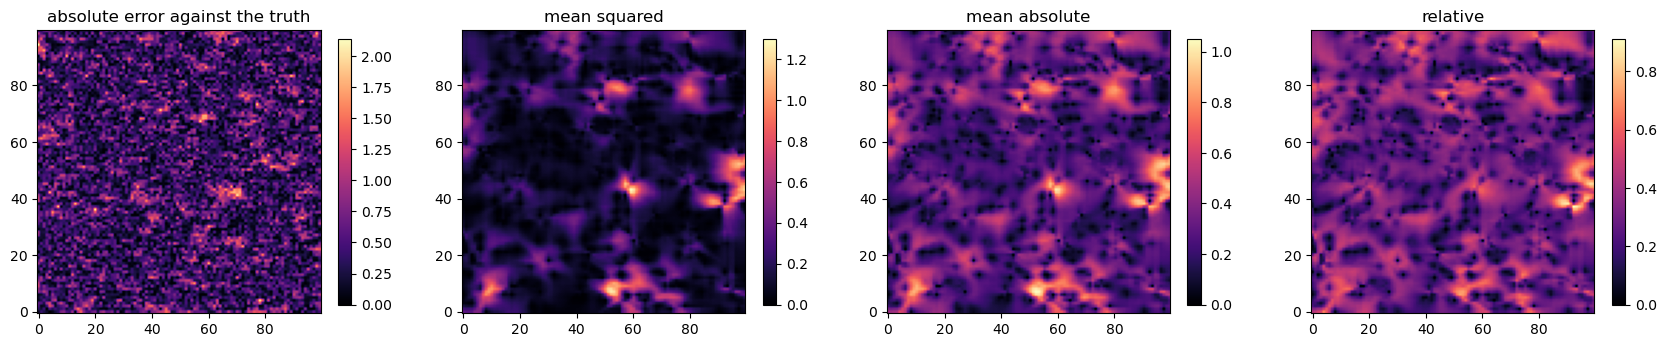

,rank correlation with the error,largest errors in the top tenth of the precision
mean squared,0.084,0.118
mean absolute,0.083,0.118
relative,0.080,0.115


In [2]:
@lf.loss(af.mean)
def relative_loss(estimate, member):
    return np.abs(member - estimate) / (np.abs(estimate) + 0.5)

precisions = {"mean squared": result.precision(), "mean absolute": result.precision(lf.mae_loss),
              "relative": result.precision(relative_loss)}
error = np.abs(estimate - truth)
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for ax, (title, z) in zip(axes, [("absolute error against the truth", error)] + list(precisions.items())):
    im = ax.imshow(z.T, origin="lower", cmap="magma")
    ax.set_title(title); fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()

top = error > np.quantile(error, 0.9)
pd.DataFrame({name: {"rank correlation with the error": spearmanr(p.ravel(), error.ravel())[0],
                     "largest errors in the top tenth of the precision": np.mean(p[top] > np.quantile(p, 0.9))}
              for name, p in precisions.items()}).T.round(3)

The precision maps light up in patches, where the partitions disagree most, while the error against the truth looks like noise spread over the whole map. Its rank
correlation with the error is 0.08 for every loss. The top tenth of the precision holds 12 % of the
largest errors, barely more than the 10 % chance would give. On this field most of the error is the
variation of the field between nearby locations, which no partition sees, so the precision says how
much the estimate depends on the partition, not how wrong it is.

### The law at one location

At one location the members form a sample. `EmpiricalModel` fits a density to it, from which come
quantiles, credible intervals and the differential entropy, a measure of how spread the law is in the
units of the variable. Simulating from the fitted laws with widening,
`ess_sample` with `FittedModelFactory(widening="skew_normal")`, gives draws of the widened law at every
location, among them this one.

simulating the widened laws at 10000 locations, 3.4 s


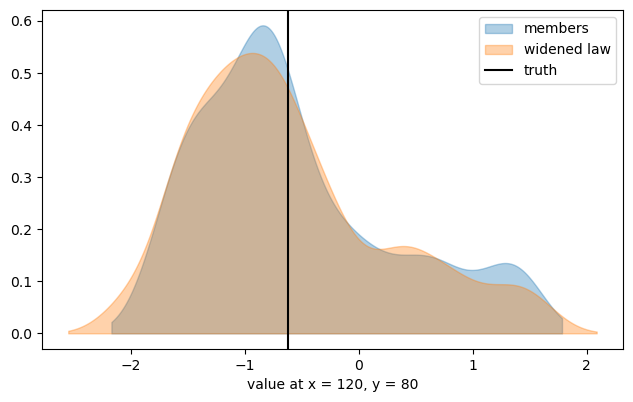

,median,90 % credible interval,entropy (nats)
members,-0.759,-1.91 to 0.99,1.161
widened law,-0.793,-1.98 to 0.93,1.211
truth,-0.622,NaN,NaN


In [3]:
start = time.perf_counter()
widened = np.asarray(ess_sample(result, n_sims=300, callback=quiet,
                                fitted_model_factory=FittedModelFactory(widening="skew_normal", seed=0)).scenarios)
widened = widened.reshape(*truth.shape, -1)
print(f"simulating the widened laws at {truth.size} locations, {time.perf_counter() - start:.1f} s")

i, j = 60, 40                                     # x = 120, y = 80
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for name, sample, colour in (("members", members[i, j], "C0"), ("widened law", widened[i, j], "C1")):
    model = EmpiricalModel(sample=sample)
    ax.fill_between(model.x_, model.pdf(model.x_), color=colour, alpha=0.35, label=name)
ax.axvline(truth[i, j], color="black", label="truth")
ax.set_xlabel("value at x = 120, y = 80"); ax.legend()
plt.show()

rows = {}
for name, sample in (("members", members[i, j]), ("widened law", widened[i, j])):
    model = EmpiricalModel(sample=sample)
    interval = model.credible_interval(model.median(), alpha=0.9)["interval"]
    rows[name] = {"median": round(float(np.squeeze(model.median())), 3), "90 % credible interval": f"{interval[0]:.2f} to {interval[1]:.2f}",
                  "entropy (nats)": round(model.entropy(), 3)}
rows["truth"] = {"median": round(truth[i, j], 3)}
pd.DataFrame(rows).T

At this location the members spread widely, from about −2 to 1.8. The truth, −0.62, lies near the
middle of both laws. The widened law adds a little to each tail. The 90 % credible intervals, around the
median, run from −1.91 to 0.99 for the members and from −1.98 to 0.93 for the widened law, with
entropies of 1.16 and 1.21 nats, about those of a normal law of spread 0.8. The widening adds little to members that already spread this much.

### Laws everywhere, at two granularities

Over the whole grid, the 90 % interval of a law should hold the truth at nine locations in ten, and the
probability of exceeding 1 should match the event. We compare the members with the widened laws at the
granularity of the knee and at a coarser one, `alpha=0.8`, whose cells are larger.

In [4]:
def readings(sample):
    low, high = np.percentile(sample, [5, 95], axis=-1)
    return {"90 % coverage": np.mean((low <= truth) & (truth <= high)), "mean width of the interval": np.mean(high - low),
            "Brier score, Z > 1": np.mean((np.mean(sample > 1.0, axis=-1) - (truth > 1.0)) ** 2)}

rows = {}
for a in (alpha, 0.8):
    r = result if a == alpha else esi_griddata(points, values, xi, local_interpolator="sharpidw", n_partitions=300,
                                               alpha=a, seed=0)
    w = widened if a == alpha else np.asarray(ess_sample(r, n_sims=300, callback=quiet, fitted_model_factory=FittedModelFactory(
        widening="skew_normal", seed=0)).scenarios).reshape(*truth.shape, -1)
    rows[f"members, alpha {a}"] = readings(r.esi_samples())
    rows[f"widened law, alpha {a}"] = readings(w)
pd.DataFrame(rows).T.round(3)

,90 % coverage,mean width of the interval,"Brier score, Z > 1"
"members, alpha 0.95",0.644,1.205,0.085
"widened law, alpha 0.95",0.904,2.121,0.081
"members, alpha 0.8",0.461,0.772,0.092
"widened law, alpha 0.8",0.904,2.116,0.082


The members' 90 % intervals hold the truth at 64 % of the locations at the knee and at 46 % with the
larger cells, their width falling from 1.21 to 0.77. Their spread follows the granularity. The widened
laws hold it at 90.4 % at both granularities, with a width of 2.12, since the widening matches the
variance of the nearest data, a property of the field. The probability of exceeding 1 improves too, its
Brier score falling from 0.085 to 0.081 at the knee and from 0.092 to 0.082 with the larger cells.

## Pitfalls

- **The precision read as the error.** It measures the spread of the members around the estimate, how
  much the estimate depends on the partition. It points at the doubtful places only as far as that
  spread follows the error, which the table above measures.
- **The members of an averaging decoder read as the law of the value.** Their spread follows the size of
  the cells, so their intervals cover far less than they claim. Widen them, or use a drawing decoder.
- **Widening taken as calibrated.** It matches the variance of the nearest data, a target that can
  overshoot. Check the coverage where a truth exists, on a simulation like your field.
- **A widened law without a seed.** The widening draws at random. Give `FittedModelFactory` a `seed` for
  reproducible laws.
- **Whole-map questions read from the widened laws.** Their draws are independent from one location to
  the next. Read an area or a total from the members.

## Try it yourself

1. Use `widening="gamma"` on a positive variable, such as the elevation of `load_elevation_walker_lake`.
2. Write a loss that counts only under-estimation, and map its precision.
3. Change `widening_knn` from 12 to 30 and compare the coverage.

## Next

- *The probabilistic decoders*, for members that carry the spread of the data without widening.
- *How many partitions?*, for the number of members a law needs.
- *Ensemble spatial simulation*, for fields drawn from the fitted laws.
- The documentation's [Ensemble spatial simulation](https://spatialize.readthedocs.io/en/latest/theory/ess.html)
  (theory) and [Loss functions](https://spatialize.readthedocs.io/en/latest/reference/functions.html) (reference).